# Multi-Head Attention para clasificar insectos

Se compara un **Vision Transformer compacto (ViT)**, entrenado desde cero, con la CNN
del laboratorio (`CNN/Cnn.ipynb` y `CNN/modelos/cnn_desde_cero.pth`).
Cada imagen se divide en 100 parches; la atención de 4 cabezas relaciona esos parches.
No se utilizan pesos preentrenados ni características extraídas de la CNN.

**Ejecutar:** abrir este notebook en la carpeta que contiene `Insectos` y `CNN`,
seleccionar el kernel de Python y ejecutar todas las celdas en orden.
Se necesita PyTorch, torchvision, numpy, pandas, matplotlib, scikit-learn y Pillow.
Si falta una biblioteca, instalarla en el mismo kernel con `%pip install nombre`.
Para instalar PyTorch con GPU, utilizar el selector de su [sitio oficial](https://pytorch.org/get-started/locally/).

Los dos modelos se evalúan sobre las mismas imágenes de prueba, sin aumentos.
Se mantienen la resolución 200×200, normalización, aumentos, muestreo balanceado,
semilla de partición 1, división 80/10/10, Adam a 0.001 y 20 épocas del laboratorio.
Se compara la **última época** de ambos modelos, sin elegir modelos mediante test.
**Hallazgo del dataset:** hay archivos idénticos entre particiones. La comparación
principal utiliza un test depurado: se excluyen copias vistas en train/validación y se
conserva una sola copia de cada archivo restante. Train y validación conservan la
división histórica para poder reutilizar los pesos de la CNN.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import random
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, classification_report, confusion_matrix,
    ConfusionMatrixDisplay)

SEED = 1
IMG_SIZE = 200
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
ENTRENAR = True  # False: cargar el resultado de una ejecución anterior.
NUM_WORKERS = 0  # Compatible con Jupyter en Windows.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semilla()
torch.set_num_threads(min(4, torch.get_num_threads()))
print('PyTorch:', torch.__version__, '| Dispositivo:', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))
else:
    print('En CPU el entrenamiento completo puede tardar bastante.')

PyTorch: 2.6.0+cu126 | Dispositivo: cuda
NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Rutas y datos

Las rutas son relativas a este notebook. Si el kernel abre otra carpeta, ajustar
`PROJECT_DIR` a la carpeta `Multi Head Atention`. No se modifica el dataset ni la CNN.

In [2]:
PROJECT_DIR = Path.cwd()
# PROJECT_DIR = Path(r'C:/ruta/a/Multi Head Atention')
if not (PROJECT_DIR / 'Insectos').is_dir() and (PROJECT_DIR.parent / 'Insectos').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
DATASET_DIR = PROJECT_DIR / 'Insectos'
CNN_DIR = PROJECT_DIR / 'CNN'
RESULTS_DIR = PROJECT_DIR / 'resultados_multi_head'
MODEL_PATH = RESULTS_DIR / 'multi_head_attention.pth'
CNN_PATH = CNN_DIR / 'modelos' / 'cnn_desde_cero.pth'
assert DATASET_DIR.is_dir(), f'No se encontró {DATASET_DIR}. Ajusta PROJECT_DIR.'
assert CNN_PATH.is_file(), f'No se encontraron los pesos originales: {CNN_PATH}'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

base = datasets.ImageFolder(DATASET_DIR)
classes = base.classes
num_classes = len(classes)
targets = np.asarray(base.targets)
print(f'{len(base):,} imágenes | {num_classes} clases')
display(pd.Series([Counter(targets)[i] for i in range(num_classes)],
                  index=classes, name='Imágenes').to_frame())

20,325 imágenes | 23 clases


,Imágenes
Abeja,1061
Abeja Malifera (Apis),477
Abejorro (Bombus),1262
Avispa,699
Chinche,476
Chinche rayada,295
Escarabajo,665
Escarabajo floricola (Oedem),297
Hormiga,1097
Lepidóptero (Mariposa-Polilla),398


In [3]:
# Se reproduce el orden de ImageFolder y las dos llamadas originales a train_test_split.
indices = list(range(len(base)))
train_idx, temp_idx, train_targets, temp_targets = train_test_split(
    indices, base.targets, test_size=0.2, stratify=base.targets, random_state=SEED)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.5, stratify=temp_targets, random_state=SEED)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(base)

# El manifiesto permite identificar exactamente qué archivos se usaron en cada partición.
filas = []
for particion, ids in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    for i in ids:
        path, label = base.samples[i]
        filas.append({'indice': i, 'archivo': Path(path).relative_to(DATASET_DIR).as_posix(),
                      'clase': classes[label], 'particion': particion,
                      'sha256': hashlib.sha256(Path(path).read_bytes()).hexdigest()})
manifest = pd.DataFrame(filas)
duplicados_cruzados = int((manifest.groupby('sha256').particion.nunique() > 1).sum())
print('Train:', len(train_idx), '| Validación:', len(val_idx), '| Test:', len(test_idx))
print('Grupos de archivos idénticos entre particiones:', duplicados_cruzados)
test_idx_historico = test_idx.copy()
hashes_vistos = set(manifest.loc[manifest.particion != 'test', 'sha256'])
test_limpio = manifest.loc[(manifest.particion == 'test') &
    ~manifest.sha256.isin(hashes_vistos)].drop_duplicates('sha256')
test_idx = test_limpio['indice'].tolist()
assert test_idx, 'No quedan imágenes de test independientes de train/val.'
assert set(targets[test_idx]) == set(range(num_classes)), 'El test depurado perdió clases.'
manifest['test_evaluado'] = manifest['indice'].isin(test_idx)
manifest.to_csv(RESULTS_DIR / 'particiones.csv', index=False, encoding='utf-8-sig')
DATA_HASH = hashlib.sha256(manifest.to_csv(index=False).encode()).hexdigest()
print('Test depurado para AMBOS modelos:', len(test_idx),
      '| Excluidas:', len(test_idx_historico) - len(test_idx))

Train: 16260 | Validación: 2032 | Test: 2033
Grupos de archivos idénticos entre particiones: 587
Test depurado para AMBOS modelos: 1715 | Excluidas: 318


La CNN no guardó un manifiesto del dataset original. Se reconstruye su partición con el
mismo algoritmo y semilla; que coincida históricamente supone que se conservaron los
mismos archivos, nombres y clases. El manifiesto nuevo registra los archivos y sus hashes.
El test depurado es un subconjunto del test histórico: sus métricas no deben confundirse
con las de las 2.033 imágenes originales. La validación aún puede contener duplicados
del entrenamiento, por lo que sus curvas pueden ser optimistas; no se utiliza para
seleccionar el checkpoint. No se puede descartar que existan imágenes similares del mismo insecto en distintas
particiones: la comprobación anterior solo detecta archivos idénticos.

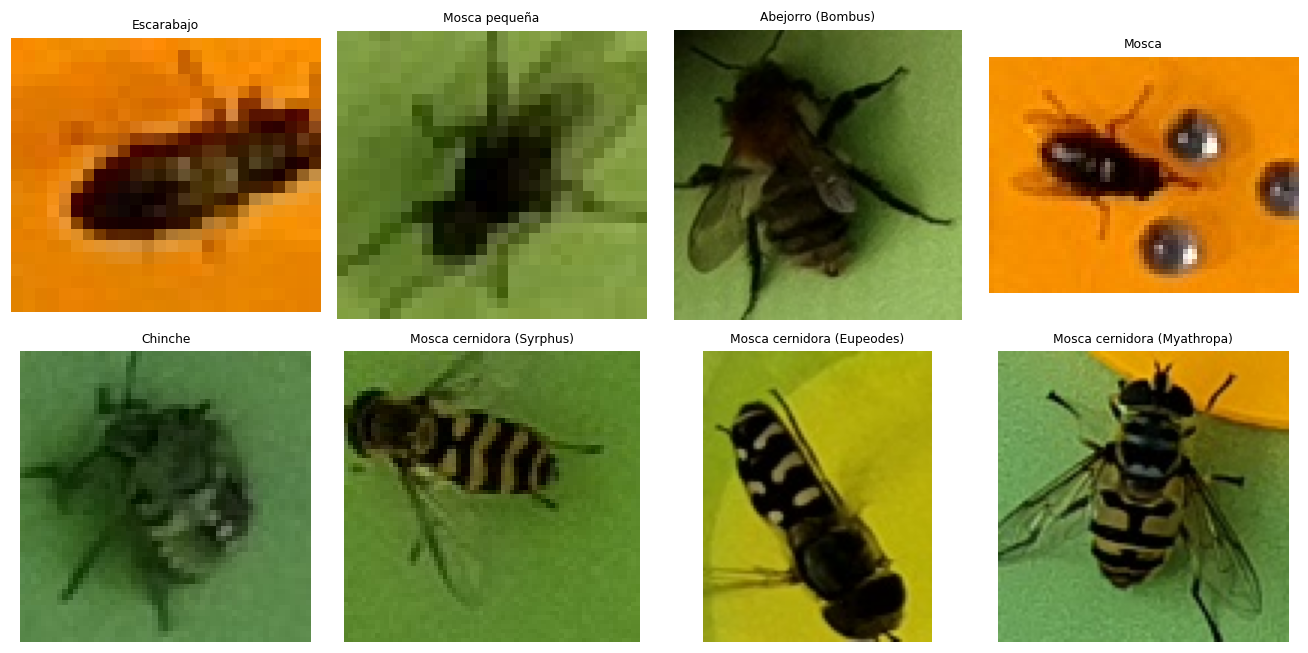

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.5),
    transforms.RandomRotation(45),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
train_data = datasets.ImageFolder(DATASET_DIR, transform=train_transform)
eval_data = datasets.ImageFolder(DATASET_DIR, transform=eval_transform)
assert train_data.samples == eval_data.samples == base.samples

def crear_train_loader():
    counts = np.bincount(np.asarray(train_targets), minlength=num_classes)
    weights = 1.0 / counts[np.asarray(train_targets)]
    sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
        len(train_idx), replacement=True, generator=torch.Generator().manual_seed(SEED))
    return DataLoader(Subset(train_data, train_idx), batch_size=BATCH_SIZE,
        sampler=sampler, num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda')

def crear_eval_loader(ids):
    return DataLoader(Subset(eval_data, ids), batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=device.type == 'cuda')

val_loader = crear_eval_loader(val_idx)
test_loader = crear_eval_loader(test_idx)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, random.Random(SEED).sample(indices, 8)):
    image, label = base[i]
    ax.imshow(image)
    ax.set_title(classes[label], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Multi-Head Attention

Un parche de 20×20 píxeles se proyecta a un vector de 128 valores.
Los 100 vectores reciben información de su posición y pasan por dos bloques:
normalización → atención de cuatro cabezas → conexión residual → red densa residual.
El promedio de los vectores produce la clasificación final.

`nn.MultiheadAttention` calcula **self-attention** porque Q, K y V son la misma secuencia.
La salida son logits: `CrossEntropyLoss` ya incorpora la operación necesaria para entrenar.
Referencias: [MultiheadAttention de PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html)
y [Vision Transformer](https://arxiv.org/abs/2010.11929).

In [5]:
class AttentionBlock(nn.Module):
    def __init__(self, dim=128, heads=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attention = nn.MultiheadAttention(dim, heads, dropout=0.1, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(),
                                 nn.Dropout(0.1), nn.Linear(dim * 2, dim), nn.Dropout(0.1))

    def forward(self, x):
        normalized = self.norm1(x)
        attended, _ = self.attention(normalized, normalized, normalized, need_weights=False)
        x = x + attended
        return x + self.mlp(self.norm2(x))

class InsectAttention(nn.Module):
    def __init__(self, n_outputs, dim=128, patch_size=20, heads=4):
        super().__init__()
        assert IMG_SIZE % patch_size == 0 and dim % heads == 0
        # Esta convolución solo proyecta parches sin solapamiento; no es la CNN del laboratorio.
        self.patches = nn.Conv2d(3, dim, kernel_size=patch_size, stride=patch_size)
        self.position = nn.Parameter(torch.zeros(1, (IMG_SIZE // patch_size) ** 2, dim))
        nn.init.trunc_normal_(self.position, std=0.02)
        self.blocks = nn.Sequential(AttentionBlock(dim, heads), AttentionBlock(dim, heads))
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, n_outputs)

    def forward(self, x):
        x = self.patches(x).flatten(2).transpose(1, 2)  # [lote, 100 parches, 128]
        x = self.blocks(x + self.position)
        return self.head(self.norm(x).mean(dim=1))

# Arquitectura idéntica a CNN/Cnn.ipynb para cargar sus pesos sin cambios.
def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))

class InsectCNN(nn.Module):
    def __init__(self, n_outputs):
        super().__init__()
        self.conv1 = block(3, 32)
        self.conv2 = block(32, 64)
        self.conv3 = block(64, 128)
        self.conv4 = block(128, 256)
        self.fc = nn.Linear(256 * 12 * 12, n_outputs)

    def forward(self, x):
        x = self.conv4(self.conv3(self.conv2(self.conv1(x))))
        return self.fc(x.flatten(1))

fijar_semilla()
modelo_mha = InsectAttention(num_classes).to(device)
modelo_cnn = InsectCNN(num_classes).to(device)
modelo_cnn.load_state_dict(torch.load(CNN_PATH, map_location=device, weights_only=True))
print('Parámetros MHA:', sum(p.numel() for p in modelo_mha.parameters()))
print('Parámetros CNN:', sum(p.numel() for p in modelo_cnn.parameters()))

Parámetros MHA: 434711
Parámetros CNN: 1236311


## 3. Entrenamiento

Solo se entrena el modelo de atención; la CNN se carga tal como quedó en el laboratorio.
La validación se usa para observar aprendizaje y sobreajuste. El test se reserva para la
evaluación final. Las pérdidas y accuracy se ponderan por número de imágenes, para que
el último lote pequeño no tenga el mismo peso que uno completo.

In [6]:
criterion = nn.CrossEntropyLoss()

def sincronizar():
    if device.type == 'cuda':
        torch.cuda.synchronize()

def una_epoca(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = correct = total = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

config = {'seed': SEED, 'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE,
          'epochs': EPOCHS, 'learning_rate': LEARNING_RATE,
          'dim': 128, 'heads': 4, 'patch_size': 20, 'blocks': 2}
if ENTRENAR:
    fijar_semilla()
    modelo_mha = InsectAttention(num_classes).to(device)
    optimizer = torch.optim.Adam(modelo_mha.parameters(), lr=LEARNING_RATE)
    train_loader = crear_train_loader()
    historial = []
    sincronizar()
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        train_loss, train_acc = una_epoca(modelo_mha, train_loader, optimizer)
        val_loss, val_acc = una_epoca(modelo_mha, val_loader)
        sincronizar()
        row = {'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc,
               'val_loss': val_loss, 'val_acc': val_acc,
               'seconds': time.perf_counter() - epoch_start}
        historial.append(row)
        print(f"Época {epoch:02d}/{EPOCHS} | loss {train_loss:.4f} | acc {train_acc:.4f} | "
              f"val_loss {val_loss:.4f} | val_acc {val_acc:.4f} | {row['seconds']:.1f}s", flush=True)
        pd.DataFrame(historial).to_csv(RESULTS_DIR / 'historial_mha.csv', index=False)
        # Copia de la última época; se puede recuperar incluso si se interrumpe después.
        torch.save({'state_dict': modelo_mha.state_dict(), 'classes': classes,
                    'config': config, 'data_hash': DATA_HASH, 'epoch': epoch,
                    'training_seconds': time.perf_counter() - start}, MODEL_PATH)
else:
    checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=True)
    assert checkpoint['classes'] == classes and checkpoint['data_hash'] == DATA_HASH
    assert checkpoint['config'] == config, 'La configuración difiere del entrenamiento guardado.'
    modelo_mha.load_state_dict(checkpoint['state_dict'])
    historial = pd.read_csv(RESULTS_DIR / 'historial_mha.csv').to_dict('records')

checkpoint = torch.load(MODEL_PATH, map_location='cpu', weights_only=True)
print('Épocas completadas:', checkpoint['epoch'])
print(f"Tiempo de entrenamiento MHA: {checkpoint['training_seconds'] / 60:.2f} minutos")
if checkpoint['epoch'] != 20:
    print('Esta ejecución tiene un presupuesto de épocas diferente de la CNN histórica (20).')

Época 01/20 | loss 2.7118 | acc 0.1910 | val_loss 2.5092 | val_acc 0.1924 | 51.3s
Época 02/20 | loss 2.1710 | acc 0.3379 | val_loss 2.1802 | val_acc 0.3376 | 52.8s
Época 03/20 | loss 1.9310 | acc 0.4045 | val_loss 2.3517 | val_acc 0.2633 | 52.7s
Época 04/20 | loss 1.8230 | acc 0.4303 | val_loss 2.0283 | val_acc 0.3361 | 53.2s
Época 05/20 | loss 1.7127 | acc 0.4670 | val_loss 1.9530 | val_acc 0.3888 | 52.6s
Época 06/20 | loss 1.5938 | acc 0.4990 | val_loss 2.0205 | val_acc 0.3632 | 53.2s
Época 07/20 | loss 1.5142 | acc 0.5289 | val_loss 2.1341 | val_acc 0.3292 | 53.5s
Época 08/20 | loss 1.4637 | acc 0.5403 | val_loss 1.6476 | val_acc 0.4779 | 52.9s
Época 09/20 | loss 1.3772 | acc 0.5699 | val_loss 1.5237 | val_acc 0.5084 | 53.1s
Época 10/20 | loss 1.3181 | acc 0.5889 | val_loss 1.6361 | val_acc 0.4887 | 52.7s
Época 11/20 | loss 1.2773 | acc 0.6028 | val_loss 2.1504 | val_acc 0.3696 | 52.8s
Época 12/20 | loss 1.2261 | acc 0.6123 | val_loss 1.7363 | val_acc 0.4606 | 53.0s
Época 13/20 | lo

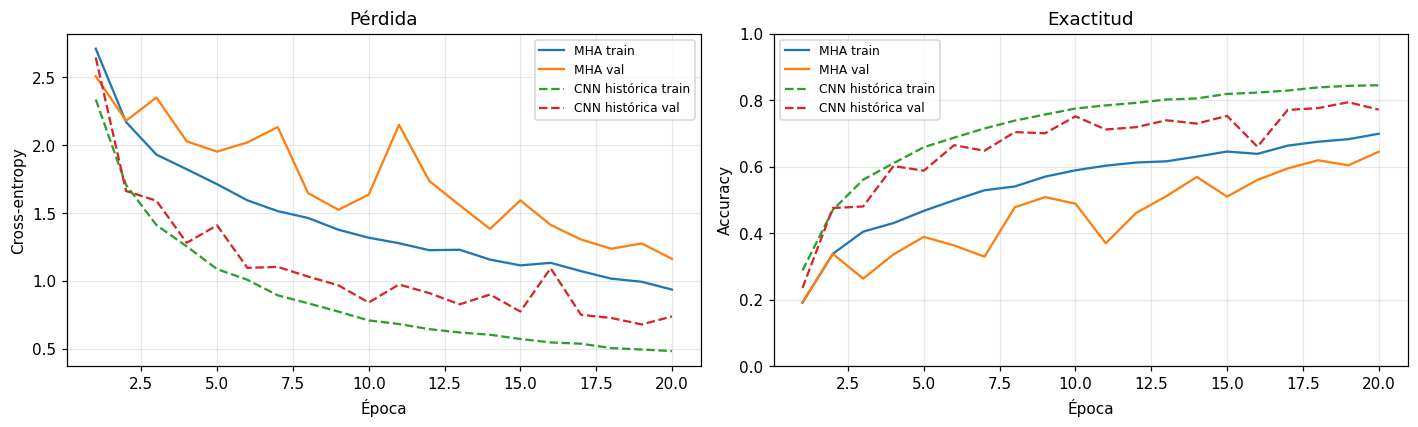

Las curvas CNN históricas promedian lotes; las nuevas curvas ponderan por imágenes.


In [7]:
# Las curvas históricas se extraen del texto guardado en el notebook original.
# No es necesario deserializar el .pt del historial, que contiene objetos numpy antiguos.
original_nb = json.loads((CNN_DIR / 'Cnn.ipynb').read_text(encoding='utf-8-sig'))
original_text = ''.join(''.join(o.get('text', [])) for c in original_nb['cells']
                        for o in c.get('outputs', []))
pattern = r'Resultado -> loss: ([0-9.]+) \| val_loss: ([0-9.]+) \| acc: ([0-9.]+) \| val_acc: ([0-9.]+)'
cnn_rows = re.findall(pattern, original_text)
hist_cnn = pd.DataFrame([[float(v) for v in row] for row in cnn_rows],
                       columns=['train_loss', 'val_loss', 'train_acc', 'val_acc'])
hist_mha = pd.DataFrame(historial)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h, style in [('MHA', hist_mha, '-'), ('CNN histórica', hist_cnn, '--')]:
    for split in ['train', 'val']:
        if not h.empty:
            x = np.arange(1, len(h) + 1)
            axes[0].plot(x, h[f'{split}_loss'], style, label=f'{name} {split}')
            axes[1].plot(x, h[f'{split}_acc'], style, label=f'{name} {split}')
axes[0].set(title='Pérdida', xlabel='Época', ylabel='Cross-entropy')
axes[1].set(title='Exactitud', xlabel='Época', ylabel='Accuracy', ylim=(0, 1))
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()
print('Las curvas CNN históricas promedian lotes; las nuevas curvas ponderan por imágenes.')

## 4. Evaluación y comparación

**Accuracy** mide aciertos globales. **Precision macro** y **recall macro** promedian las
clases por igual; el **F1 macro** resume su equilibrio sin favorecer las clases abundantes.
Balanced accuracy es el promedio del recall por clase. F1 ponderado tiene en cuenta
cuántas imágenes hay por clase. Todas estas métricas se presentan entre 0 y 1.

El tiempo de inferencia se mide por separado, con entradas ya cargadas en GPU/CPU y
calentamiento previo: excluye lectura de disco y transformaciones. El entrenamiento
histórico de la CNN no tiene un registro de tiempo estructurado comparable, por eso
se informa solo el tiempo medido del nuevo entrenamiento.

In [8]:
@torch.inference_mode()
def evaluar(model, name):
    model.eval()
    y_true, y_pred, probabilities = [], [], []
    total_loss = 0.0
    for images, labels in test_loader:
        logits = model(images.to(device))
        total_loss += criterion(logits, labels.to(device)).item() * len(labels)
        y_true.extend(labels.tolist())
        y_pred.extend(logits.argmax(1).cpu().tolist())
        probabilities.extend(logits.softmax(1).cpu().tolist())
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(num_classes)), average='macro', zero_division=0)
    weighted_f1 = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)[2]
    metrics = {'modelo': name, 'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision, 'recall_macro': recall, 'f1_macro': f1,
        'f1_ponderado': weighted_f1, 'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'test_loss': total_loss / len(y_true),
        'parametros': sum(p.numel() for p in model.parameters())}
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=list(range(num_classes)),
        target_names=classes, output_dict=True, zero_division=0)).T
    report.to_csv(RESULTS_DIR / f'reporte_{name}.csv', encoding='utf-8-sig')
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(
        RESULTS_DIR / f'matriz_{name}.csv', encoding='utf-8-sig')
    predictions = pd.DataFrame({'archivo': [Path(base.samples[i][0]).relative_to(DATASET_DIR).as_posix()
        for i in test_idx], 'real': [classes[i] for i in y_true],
        'prediccion': [classes[i] for i in y_pred]})
    predictions.to_csv(RESULTS_DIR / f'predicciones_{name}.csv', index=False, encoding='utf-8-sig')
    np.savez_compressed(RESULTS_DIR / f'probabilidades_{name}.npz',
                       y_true=y_true, probabilities=probabilities, classes=classes)
    return metrics, report, cm, np.asarray(y_true), np.asarray(y_pred)

@torch.inference_mode()
def medir_inferencia(model):
    model.eval()
    batch = next(iter(test_loader))[0].to(device)
    for _ in range(5):
        model(batch)
    # Mediana de 5 mediciones, cada una con 10 lotes idénticos.
    timings = []
    for _ in range(5):
        sincronizar()
        start = time.perf_counter()
        for _ in range(10):
            model(batch)
        sincronizar()
        timings.append((time.perf_counter() - start) / (10 * len(batch)))
    seconds_per_image = float(np.median(timings))
    return seconds_per_image * 1000, 1.0 / seconds_per_image

resultados = {}
for name, model in [('CNN', modelo_cnn), ('MHA', modelo_mha)]:
    metrics, report, cm, y_true, y_pred = evaluar(model, name)
    metrics['inferencia_ms_imagen'], metrics['imagenes_segundo'] = medir_inferencia(model)
    resultados[name] = {'metricas': metrics, 'reporte': report, 'cm': cm,
                        'real': y_true, 'pred': y_pred}
    print(name, '| Test accuracy:', round(metrics['accuracy'], 4),
          '| F1 macro:', round(metrics['f1_macro'], 4))

tabla = pd.DataFrame([r['metricas'] for r in resultados.values()]).set_index('modelo')
tabla.to_csv(RESULTS_DIR / 'comparacion_metricas.csv', encoding='utf-8-sig')
display(tabla.round(4))

CNN | Test accuracy: 0.7977 | F1 macro: 0.7407
MHA | Test accuracy: 0.6723 | F1 macro: 0.6145


,accuracy,precision_macro,recall_macro,f1_macro,f1_ponderado,balanced_accuracy,test_loss,parametros,inferencia_ms_imagen,imagenes_segundo
modelo,,,,,,,,,,
CNN,0.7977,0.7336,0.7884,0.7407,0.807,0.7884,0.6673,1236311,0.5032,1987.2672
MHA,0.6723,0.6225,0.6702,0.6145,0.669,0.6702,1.0371,434711,0.0519,19255.8226


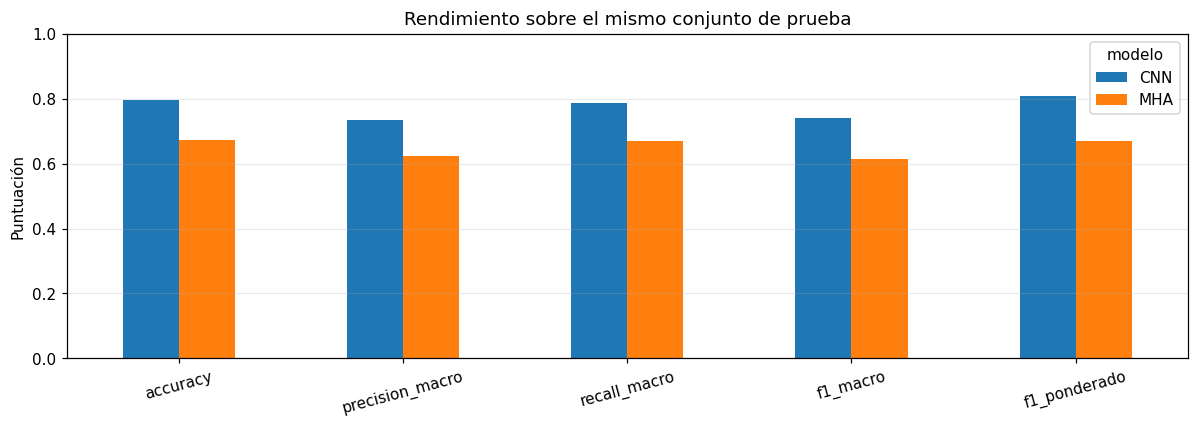

REPORTE POR CLASE — CNN


,precision,recall,f1-score,support
Abeja,0.568,0.745,0.645,106.000
Abeja Malifera (Apis),0.467,0.636,0.538,11.000
Abejorro (Bombus),1.000,0.897,0.946,126.000
Avispa,0.886,0.951,0.918,41.000
Chinche,0.460,0.853,0.598,34.000
Chinche rayada,1.000,1.000,1.000,6.000
Escarabajo,0.630,0.447,0.523,38.000
Escarabajo floricola (Oedem),0.214,0.600,0.316,10.000
Hormiga,0.911,0.836,0.872,110.000
Lepidóptero (Mariposa-Polilla),0.300,1.000,0.462,9.000


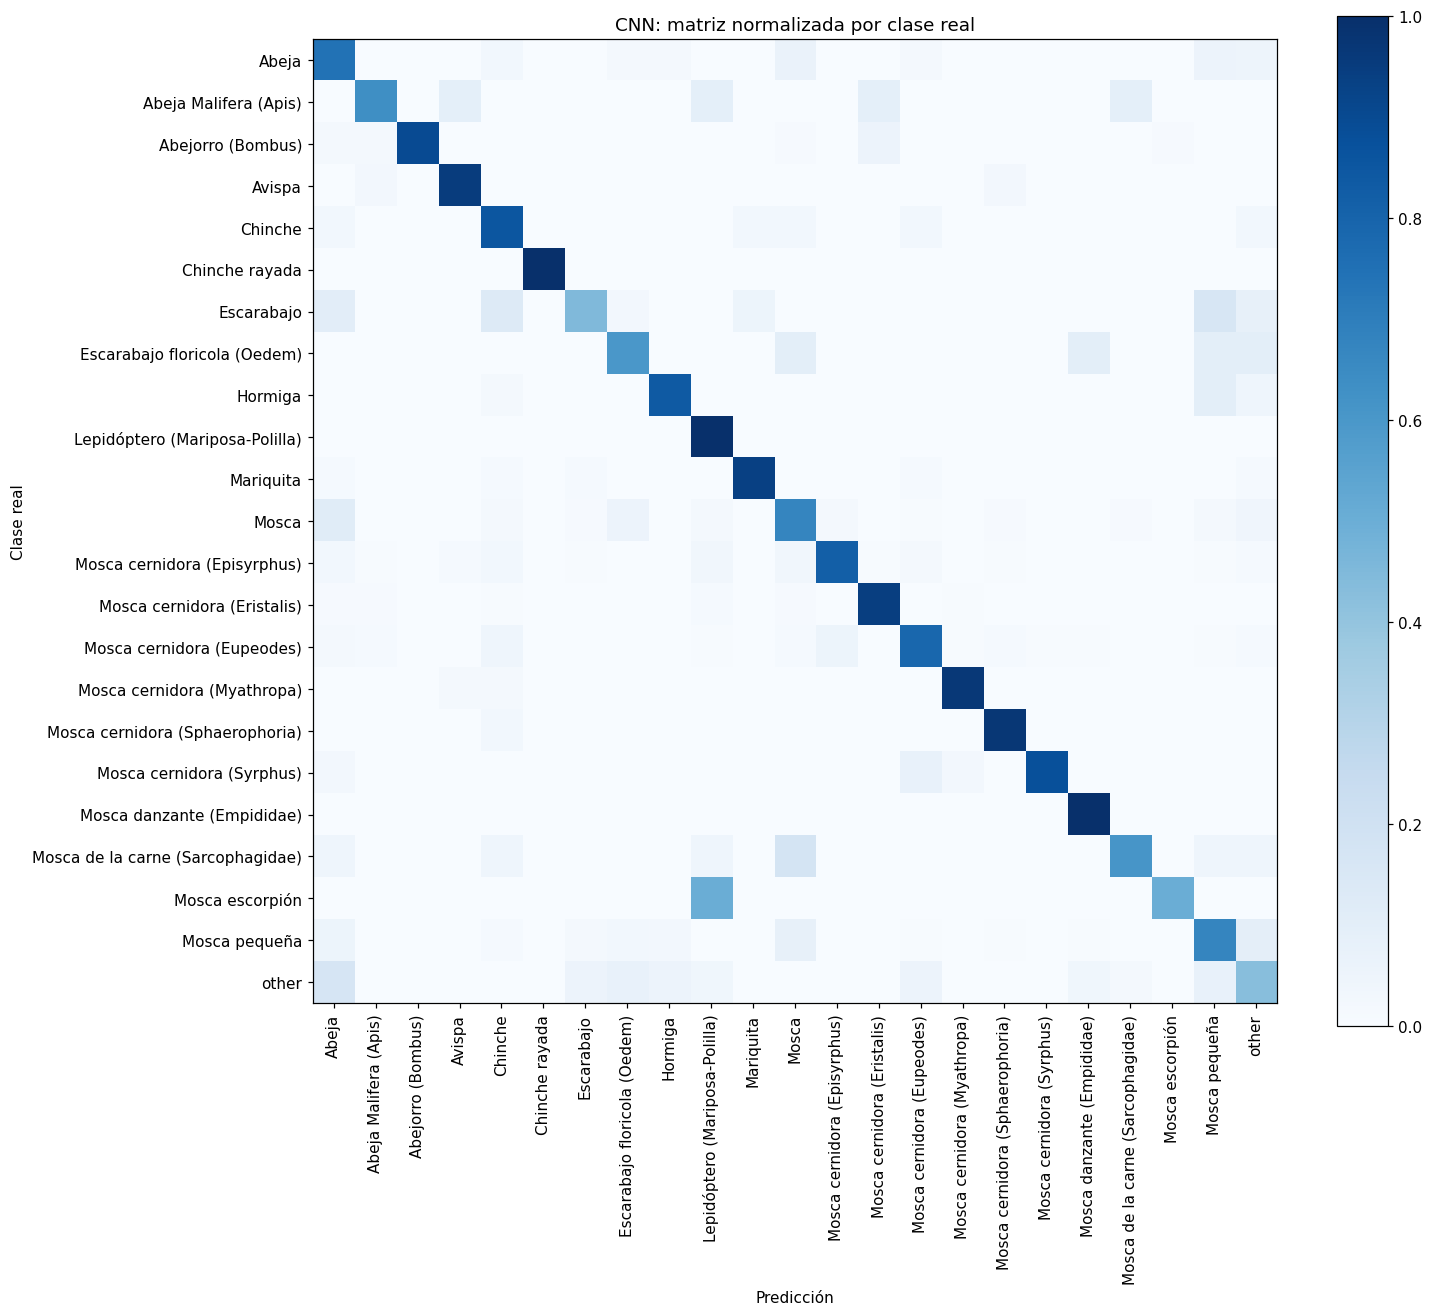

REPORTE POR CLASE — MHA


,precision,recall,f1-score,support
Abeja,0.556,0.236,0.331,106.000
Abeja Malifera (Apis),1.000,0.545,0.706,11.000
Abejorro (Bombus),0.954,0.659,0.779,126.000
Avispa,0.733,0.805,0.767,41.000
Chinche,0.324,0.647,0.431,34.000
Chinche rayada,1.000,1.000,1.000,6.000
Escarabajo,0.348,0.605,0.442,38.000
Escarabajo floricola (Oedem),0.176,0.300,0.222,10.000
Hormiga,0.798,0.900,0.846,110.000
Lepidóptero (Mariposa-Polilla),0.500,0.889,0.640,9.000


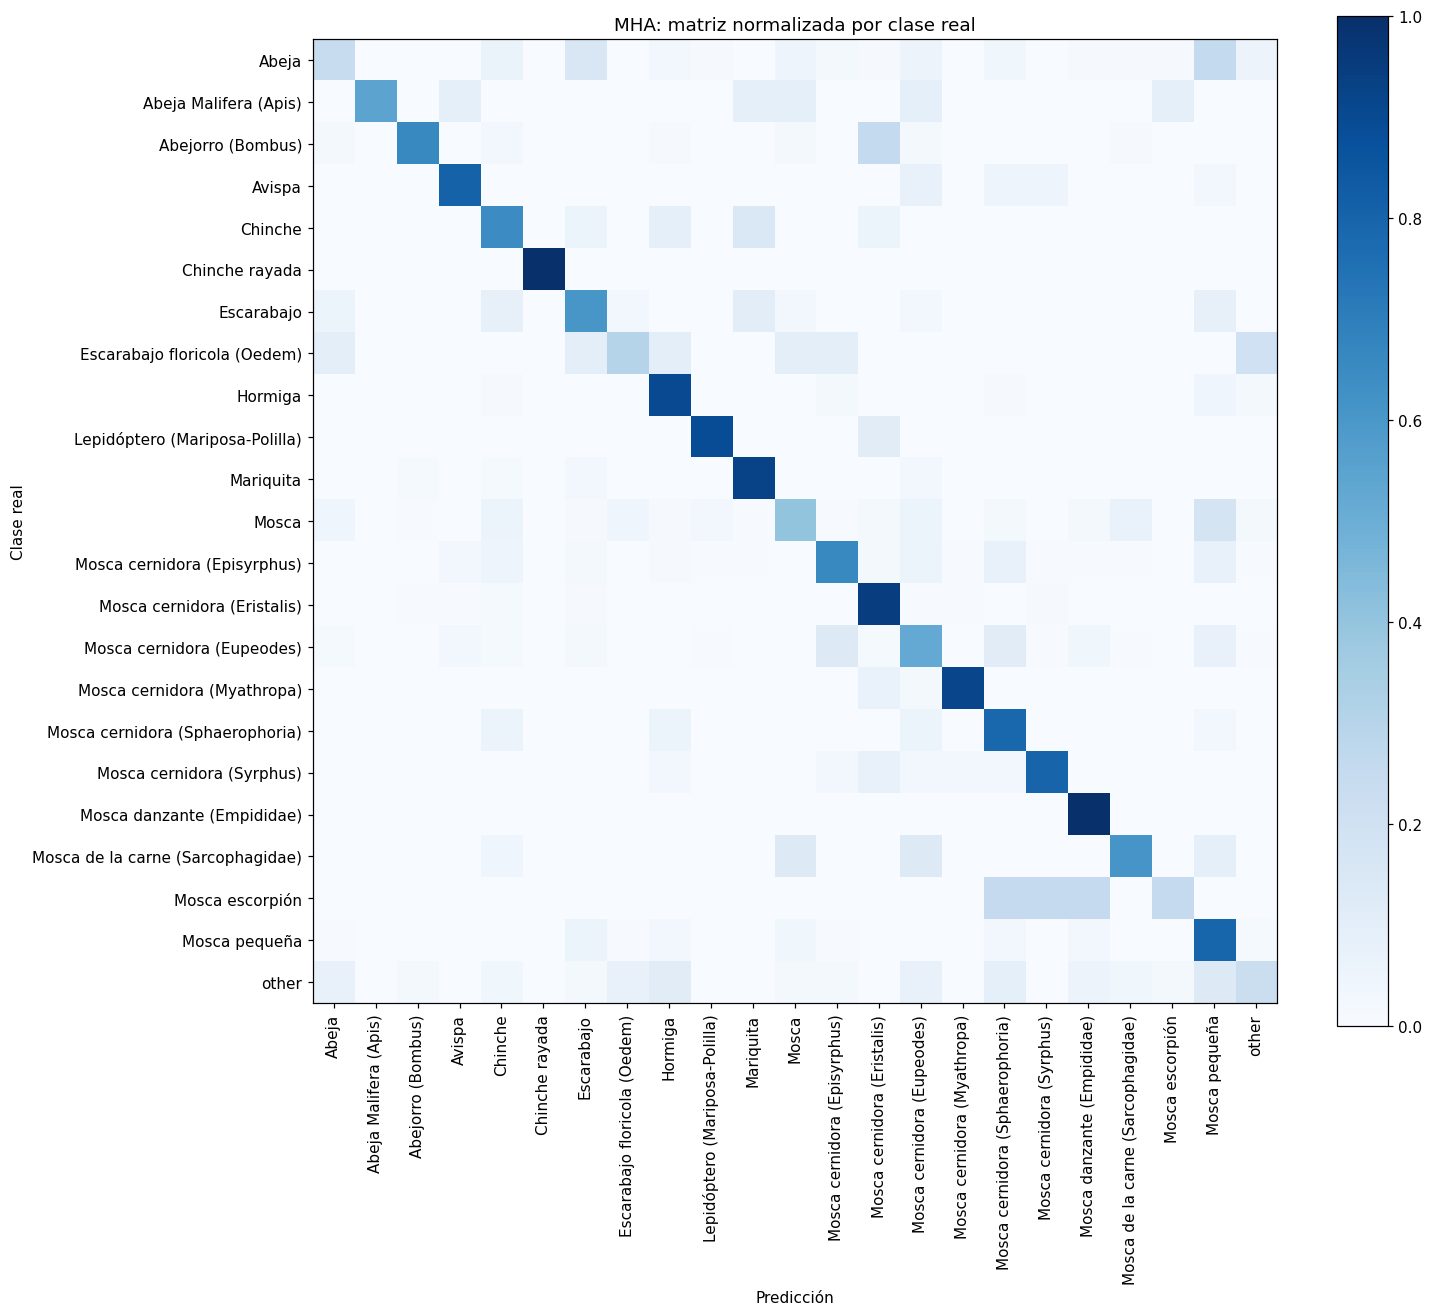

In [9]:
metricas_grafico = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_ponderado']
ax = tabla[metricas_grafico].T.plot.bar(figsize=(11, 4), ylim=(0, 1), rot=15)
ax.set(title='Rendimiento sobre el mismo conjunto de prueba', ylabel='Puntuación')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'comparacion_metricas.png', dpi=150, bbox_inches='tight')
plt.show()

for name, result in resultados.items():
    print(f'REPORTE POR CLASE — {name}')
    display(result['reporte'].round(3))
    cm = result['cm'].astype(float)
    normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(14, 12))
    ConfusionMatrixDisplay(normalized, display_labels=classes).plot(
        ax=ax, cmap='Blues', include_values=False, xticks_rotation=90, colorbar=True)
    ax.set(title=f'{name}: matriz normalizada por clase real',
           xlabel='Predicción', ylabel='Clase real')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'matriz_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()